# 0. Entendendo o problema e os dados



### 1. Objetivo
O projeto busca ajudar pessoas a avaliar a confiabilidade de informações **sem substituir seu pensamento crítico**: o sistema devolve um dossiê de evidências, nunca um veredito de "falso" ou "verdadeiro".

Esta análise verifica se o **FACTCK.BR** pode servir de base de conhecimento (corpus do RAG) para o Agente de Evidências. O objetivo **não** é treinar um classificador de fake news.

### 2. Variáveis
O dataset tem **1.313 linhas e 9 colunas**; cada linha é uma alegação checada por uma agência brasileira.

- **URL**: endereço da checagem
- **Author**: agência (Lupa, Aos Fatos ou Truco/Agência Pública)
- **datePublished**: data de publicação
- **claimReviewed**: alegação checada
- **reviewBody**: resumo da checagem
- **title**: título do artigo
- **ratingValue**: nota numérica da agência
- **bestRating**: tamanho da escala da nota
- **alternativeName**: rótulo textual (ex.: "falso", "exagerado")

### 3. Tipos de dados
- **Texto:** `claimReviewed`, `reviewBody`, `title`
- **Categóricos:** `Author` (3 agências), `alternativeName` (14 rótulos)
- **Numéricos:** `ratingValue`, `bestRating` (na prática, códigos de categoria)
- **Data:** `datePublished`
- **Identificador:** `URL` (não é única)

### 4. Problemas de qualidade e limitações

**Qualidade**
- A Lupa usa a palavra "Empty" em vez de valor nulo no `reviewBody`; no total, 41% das linhas ficam sem texto de checagem.
- As datas vêm em formatos mistos (com e sem hora).
- Os rótulos têm grafia inconsistente ("Falso" / "falso").
- As notas não são comparáveis: cada agência usa uma escala (5, 6 e 8), e a Lupa atribui nota 4 a todas as linhas.
- Há 91 URLs repetidas (420 linhas), porque uma checagem pode avaliar várias alegações.
- 36 "alegações" têm mais de 60 palavras; na verdade, são o texto inteiro da checagem.

**Limitações**
- Período desatualizado: 2016 a 2019.
- Apenas 3 agências e 1.313 linhas.
- 72% dos rótulos são "falso", por viés de seleção das agências.
- Predomínio de temas políticos e eleitorais.

**Conclusão:** o FACTCK.BR serve para prototipar o pipeline e para a EDA, mas precisa ser complementado pela coleta via Google Fact Check Tools API.

# 1. Carregamento e Inspeção Inicial

In [4]:
from IPython.display import display
import pandas as pd
import numpy as np

# =============================================================
# 1. CARREGAMENTO E INSPEÇÃO INICIAL
# Esta seção apenas diagnostica; nada é alterado no dataset.
# As correções são aplicadas na seção 2.
# =============================================================

URL = "https://raw.githubusercontent.com/jghm-f/FACTCK.BR/master/FACTCKBR.tsv"
df = pd.read_csv(URL, sep="\t")   # arquivo separado por tabulação
display(df.head())

,URL,Author,datePublished,claimReviewed,reviewBody,title,ratingValue,bestRating,alternativeName
0,https://aosfatos.org/noticias/governo-bolsonar...,https:www.aosfatos.org,2019-07-22,Espaço dedicado para os eleitores do Bolsonaro...,Publicações que circulam nas redes sociais vej...,Governo Bolsonaro não suspendeu distribuição d...,1.0,5,falso
1,https://aosfatos.org/noticias/nao-e-miriam-lei...,https:www.aosfatos.org,2019-07-22,Vos apresento a funcionária protegida pela Glo...,Uma foto de um treinamento de defesa contra as...,Não é Miriam Leitão quem segura fuzil ao lado ...,1.0,5,falso
2,https://aosfatos.org/noticias/nao-e-verdade-qu...,https:www.aosfatos.org,2019-07-22,Você sabia que Benedita da Silva já foi embaix...,falsa a informação de que a deputada federal ...,Não é verdade que Benedita da Silva foi embaix...,1.0,5,falso
3,https://aosfatos.org/noticias/nao-e-de-mulher-...,https:www.aosfatos.org,2019-07-18,QUEM A MULHER QUE EMPURROU O PADRE MARCELO ROSSI,Modificada digitalmente para incluir o filtro ...,Não é de mulher que empurrou padre Marcelo Ros...,1.0,5,falso
4,https://aosfatos.org/noticias/e-falso-que-refo...,https:www.aosfatos.org,2019-07-17,As crueldades da Reforma da PrevidênciaPessoas...,Uma publicação que circula nas redes sociais a...,É falso que reforma tira de pessoas com defici...,1.0,5,falso


In [5]:
# --- 1.1 Número de linhas e colunas --------------------------
print(f"O dataset tem {df.shape[0]} linhas e {df.shape[1]} colunas\n")

# --- 1.2 Valores ausentes ------------------------------------
# A coluna "texto 'Empty'" existe porque há ausentes disfarçados
# de texto, que o isna() sozinho não encontra: a Lupa grava a
# palavra "Empty" no lugar do reviewBody.
ausentes = pd.DataFrame({
    "nulos": df.isna().sum(),
    "texto 'Empty'": (df == "Empty").sum(),
})
ausentes["total"] = ausentes.sum(axis=1)
ausentes["% do total"] = (ausentes["total"] / len(df) * 100).round(1)
display(ausentes)

# --- 1.3 Tipo de cada variável -------------------------------
# datePublished foi lida como texto, mas é data. A conversão
# exige format="mixed" e é feita na seção 2.
print("\nTipos de dados:")
print(df.dtypes, "\n")

# --- 1.4.1 Categorias escritas de formas diferentes ----------
# Author guarda a URL malformada da agência (sem as barras);
# alternativeName mistura maiúsculas e minúsculas.
print("Agências (Author):")
print(df["Author"].unique(), "\n")
print("Rótulos (alternativeName):")
print(sorted(df["alternativeName"].dropna().unique()), "\n")

# --- 1.4.2 Notas fora da escala ------------------------------
print("Notas inválidas (acima da escala ou abaixo de 1):")
display(df[(df["ratingValue"] > df["bestRating"]) | (df["ratingValue"] < 1)][
    ["Author", "ratingValue", "bestRating", "alternativeName"]])

# A Lupa usa nota 4 em todas as linhas, qualquer que seja o rótulo.
# Somado às escalas diferentes, isso torna a nota incomparável:
# ratingValue e bestRating são descartadas na seção 2.
print("\nNotas usadas por agência:")
print(df.groupby("Author")["ratingValue"].unique(), "\n")

# --- 1.4.3 Duplicatas ----------------------------------------
# URLs repetidas não são erro: uma checagem pode avaliar várias
# alegações. Alegações repetidas são a mesma frase checada por
# agências diferentes.
print("Linhas idênticas:", df.duplicated().sum())
print("URLs repetidas:", df["URL"].duplicated().sum())
print("Alegações repetidas:", df["claimReviewed"].dropna().duplicated().sum(), "\n")

# --- 1.4.4 Tamanhos incomuns de alegação ---------------------
# Sem fillna: linhas sem alegação ficam NaN em vez de "0 palavras".
# A variável não é gravada no df para não poluir o df_limpo.
n_palavras = df["claimReviewed"].str.split().str.len()
print("Palavras por alegação:")
print(n_palavras.describe().round(1))
print(f"\nAlegações com mais de 60 palavras: {(n_palavras > 60).sum()}")
display(df.loc[n_palavras > 60, ["Author", "claimReviewed"]].assign(n_palavras=n_palavras))

O dataset tem 1313 linhas e 9 colunas



,nulos,texto 'Empty',total,% do total
URL,0,0,0,0.0
Author,0,0,0,0.0
datePublished,0,0,0,0.0
claimReviewed,13,0,13,1.0
reviewBody,12,528,540,41.1
title,0,0,0,0.0
ratingValue,4,0,4,0.3
bestRating,0,0,0,0.0
alternativeName,4,0,4,0.3



Tipos de dados:
URL                    str
Author                 str
datePublished          str
claimReviewed          str
reviewBody             str
title                  str
ratingValue        float64
bestRating           int64
alternativeName        str
dtype: object 

Agências (Author):
<StringArray>
[          'https:www.aosfatos.org',               'https:apublica.org',
 'https:piaui.folha.uol.com.brlupa']
Length: 3, dtype: str 

Rótulos (alternativeName):
['Ainda é cedo para dizer', 'De olho', 'Discutível', 'Distorcido', 'Exagerado', 'Falso', 'Impossível provar', 'Sem contexto', 'Subestimado', 'Verdadeiro', 'Verdadeiro, mas', 'distorcido', 'exagerado', 'falso', 'impreciso', 'insustentável', 'outros', 'verdadeiro'] 

Notas inválidas (acima da escala ou abaixo de 1):


,Author,ratingValue,bestRating,alternativeName
360,https:www.aosfatos.org,6.0,5,verdadeiro
369,https:www.aosfatos.org,0.0,5,outros



Notas usadas por agência:
Author
https:apublica.org                  [1.0, 6.0, 8.0, 4.0, 2.0, 5.0, 7.0, nan, 3.0]
https:piaui.folha.uol.com.brlupa                                            [4.0]
https:www.aosfatos.org                        [1.0, 3.0, 5.0, 4.0, 2.0, 6.0, 0.0]
Name: ratingValue, dtype: object 

Linhas idênticas: 0
URLs repetidas: 329
Alegações repetidas: 9 

Palavras por alegação:
count    1300.0
mean       23.0
std        60.0
min         3.0
25%        11.0
50%        16.0
75%        24.0
max      1599.0
Name: claimReviewed, dtype: float64

Alegações com mais de 60 palavras: 36


,Author,claimReviewed,n_palavras
18,https:www.aosfatos.org,"Durante os governos Lula, Dilma e Temer, os av...",90.0
76,https:www.aosfatos.org,"O PT é tão sacana, que até o padre que foi vis...",78.0
87,https:www.aosfatos.org,NARCOTRFICO & COMUNISMO. Em 2015 eu postei est...,65.0
120,https:www.aosfatos.org,Dilma Rousseff: A lua é muito mais importante ...,78.0
134,https:www.aosfatos.org,S.S.O TAPA NA CARA DA NAO. ..!!!DESABAFO ... ...,305.0
171,https:www.aosfatos.org,Existem rumores de que a renúncia ao mandato d...,93.0
177,https:www.aosfatos.org,O PT criou 9 vice presidências com salários de...,72.0
214,https:www.aosfatos.org,Polícia federal.Porto de Santos. 60 baús de me...,74.0
218,https:www.aosfatos.org,"Todo produto encaixado leite, creme de leite, ...",63.0
221,https:www.aosfatos.org,"Segundo o embaixador da China no Brasil, Li Ji...",64.0


# 2. Tratamento dos Dados

In [6]:
# =============================================================
# 2. TRATAMENTO DOS DADOS
# Cria o df_limpo a partir do df bruto da seção 1.
# Princípio: nada de imputar texto ou rótulo — ausente que não
# pode ser recuperado da fonte continua sinalizado como ausente.
# =============================================================

# --- 2.1 Tornar visíveis os ausentes disfarçados de texto ----
df["reviewBody"] = df["reviewBody"].replace("Empty", np.nan)

# --- 2.2 Entender o padrão dos ausentes ----------------------
cols = ["claimReviewed", "reviewBody", "alternativeName"]
print("Ausentes por agência:")
print(df[cols].isna().groupby(df["Author"]).sum(), "\n")

# Os ausentes do Aos Fatos se concentram no período eleitoral de 2018,
# o que sugere falha de coleta e não ausência real.
af = df["Author"].str.contains("aosfatos") & df["reviewBody"].isna()
print("Datas dos ausentes do Aos Fatos:")
print(sorted(df.loc[af, "datePublished"].unique()), "\n")

# --- 2.3 Registrar onde havia ausentes, antes de tratar ------
# Estes indicadores mostram quais linhas precisarão da extração via URL.
df["tem_alegacao"] = df["claimReviewed"].notna()
df["tem_review"] = df["reviewBody"].notna()

# --- 2.4 Aplicar as decisões de tratamento -------------------
df_limpo = df.copy()

# Rótulo ausente vira categoria explícita: estimá-lo seria inventar
# uma conclusão que a agência nunca publicou.
df_limpo["alternativeName"] = df_limpo["alternativeName"].fillna("não informado")

# Notas descartadas: escalas diferentes por agência e valor constante na Lupa.
df_limpo = df_limpo.drop(columns=["ratingValue", "bestRating"])

# Remove só a linha sem nada aproveitável (sem alegação, texto ou rótulo).
vazia = (~df_limpo["tem_alegacao"]
         & ~df_limpo["tem_review"]
         & (df_limpo["alternativeName"] == "não informado"))
df_limpo = df_limpo[~vazia]

# --- 2.5 Padronizar categorias, datas e colunas derivadas ----
AGENCIAS = {
    "https:piaui.folha.uol.com.brlupa": "Lupa",
    "https:apublica.org": "Truco",
    "https:www.aosfatos.org": "Aos Fatos",
}
df_limpo["agencia"] = df_limpo["Author"].map(AGENCIAS)

# format="mixed" porque a Lupa registra data e hora; as outras, só a data.
df_limpo["data"] = pd.to_datetime(df_limpo["datePublished"], format="mixed")

# Unifica "Falso" e "falso" num único rótulo.
df_limpo["rotulo"] = df_limpo["alternativeName"].str.strip().str.lower()

# Sem fillna: linhas sem alegação ficam NaN em vez de "0 palavras".
df_limpo["n_palavras"] = df_limpo["claimReviewed"].str.split().str.len()
df_limpo["alegacao_suspeita"] = df_limpo["n_palavras"] > 60

# Quantas alegações compartilham a mesma URL: importante para não
# deduplicar por URL e acabar fundindo alegações diferentes.
df_limpo["n_alegacoes_url"] = df_limpo.groupby("URL")["URL"].transform("size")

# --- 2.6 Conferência final -----------------------------------
print(f"Antes: {df.shape} | Depois: {df_limpo.shape}\n")
print("Ausentes restantes:")
print(df_limpo[cols].isna().sum(), "\n")
print(df_limpo["agencia"].value_counts(), "\n")
print("Rótulos distintos:", df_limpo["rotulo"].nunique())
print("Período:", df_limpo["data"].min().date(), "a", df_limpo["data"].max().date())
print("Alegações suspeitas (>60 palavras):", int(df_limpo["alegacao_suspeita"].sum()))
print("Linhas em URLs com várias alegações:", int((df_limpo["n_alegacoes_url"] > 1).sum()))

# Salva o resultado para as próximas etapas não dependerem de reexecutar tudo.
df_limpo.to_csv("factckbr_limpo.csv", index=False)

Ausentes por agência:
                                  claimReviewed  reviewBody  alternativeName
Author                                                                      
https:apublica.org                            1           1                4
https:piaui.folha.uol.com.brlupa              3         528                0
https:www.aosfatos.org                        9          11                0 

Datas dos ausentes do Aos Fatos:
['2018-10-01', '2018-10-07', '2018-10-11', '2018-10-16', '2018-10-27', '2018-11-22', '2018-11-27', '2018-11-29', '2018-12-07', '2018-12-13', '2018-12-21'] 

Antes: (1313, 11) | Depois: (1312, 15)

Ausentes restantes:
claimReviewed       12
reviewBody         539
alternativeName      0
dtype: int64 

agencia
Lupa         528
Truco        414
Aos Fatos    370
Name: count, dtype: int64 

Rótulos distintos: 15
Período: 2016-02-26 a 2019-07-22
Alegações suspeitas (>60 palavras): 36
Linhas em URLs com várias alegações: 420


# 3. ANÁLISE EXPLORATÓRIA (UNIVARIADA)

Checagens por ano e agência:
agencia  Aos Fatos  Lupa  Truco
data                           
2016             0     0     78
2017             0     0    124
2018           175   216    212
2019           195   312      0 



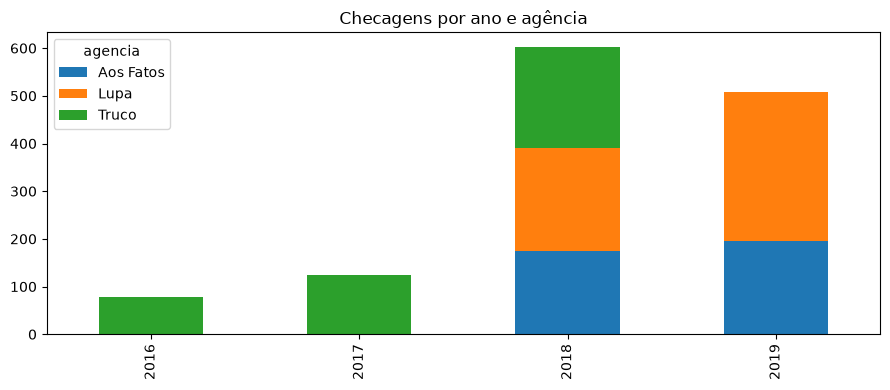

Participação de cada agência:
agencia
Lupa         40.2
Truco        31.6
Aos Fatos    28.2
Name: proportion, dtype: float64 

Rótulos por agência:
agencia                  Aos Fatos  Lupa  Truco
rotulo                                         
ainda é cedo para dizer          0     6      0
de olho                          0     3      0
discutível                       0     0     12
distorcido                      29     0     25
exagerado                        4    12     75
falso                          328   469    146
impossível provar                0     0     20
impreciso                        2     0      0
insustentável                    5     0      0
não informado                    0     0      3
outros                           1     0      0
sem contexto                     0     0     42
subestimado                      0     0      6
verdadeiro                       1    34     85
verdadeiro, mas                  0     4      0 

Concentração no rótulo 'falso': 71

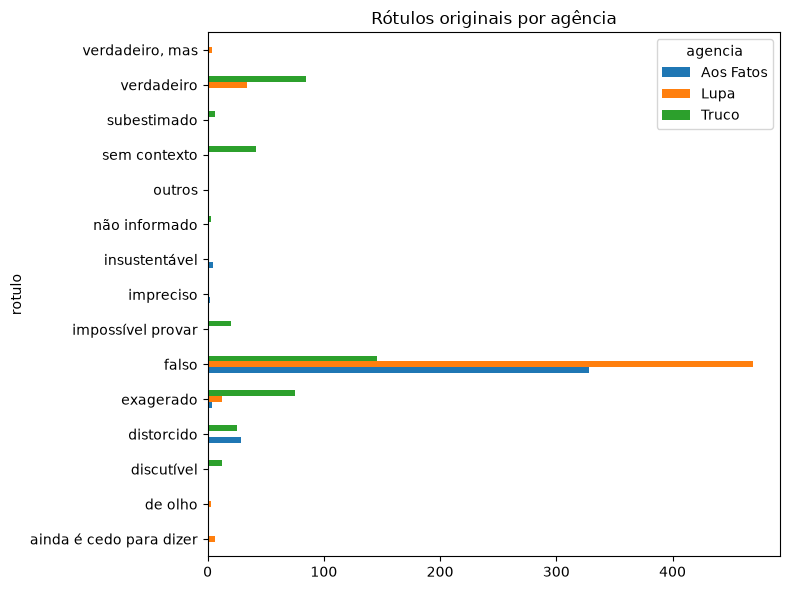

Palavras por alegação:
count    1300.0
mean       23.0
std        60.0
min         3.0
25%        11.0
50%        16.0
75%        24.0
max      1599.0
Name: n_palavras, dtype: float64 

Mediana por agência:
agencia
Aos Fatos    17.0
Lupa         14.0
Truco        16.0
Name: n_palavras, dtype: float64 



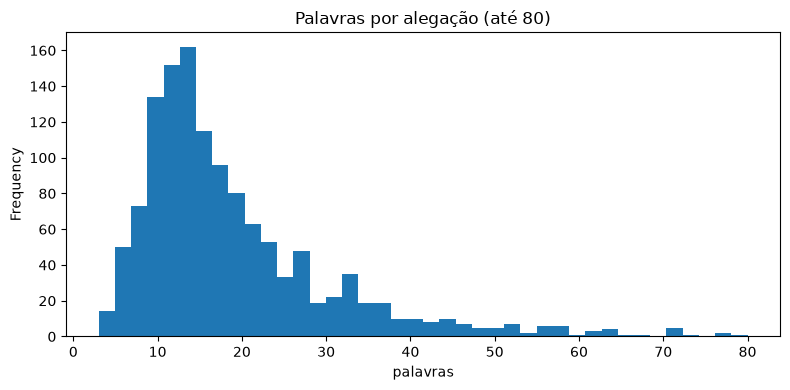

In [7]:
# =============================================================
# 3. ANÁLISE EXPLORATÓRIA (UNIVARIADA)
# Cada bloco responde a uma pergunta que afeta uma decisão do projeto.
# =============================================================
import matplotlib.pyplot as plt

# --- 3.1 Cobertura temporal ----------------------------------
# Pergunta: o corpus cobre o período que o sistema precisa?
por_ano = df_limpo.groupby([df_limpo["data"].dt.year, "agencia"]).size().unstack(fill_value=0)
print("Checagens por ano e agência:")
print(por_ano, "\n")

por_ano.plot(kind="bar", stacked=True, figsize=(9, 4),
             title="Checagens por ano e agência")
plt.xlabel(""); plt.tight_layout(); plt.show()

# --- 3.2 Distribuição por agência ----------------------------
# Pergunta: o corpus é equilibrado entre as fontes?
print("Participação de cada agência:")
print((df_limpo["agencia"].value_counts(normalize=True) * 100).round(1), "\n")

# --- 3.3 Rótulos ---------------------------------------------
# Pergunta: que rótulos o sistema terá de apresentar com atribuição?
tab = pd.crosstab(df_limpo["rotulo"], df_limpo["agencia"])
print("Rótulos por agência:")
print(tab, "\n")
print("Concentração no rótulo 'falso':",
      f"{(df_limpo['rotulo'] == 'falso').mean():.1%}\n")

tab.plot(kind="barh", figsize=(8, 6), title="Rótulos originais por agência")
plt.tight_layout(); plt.show()

# --- 3.4 Tamanho das alegações -------------------------------
# Pergunta: as alegações são atômicas, como o Claim Extractor espera?
print("Palavras por alegação:")
print(df_limpo["n_palavras"].describe().round(1), "\n")
print("Mediana por agência:")
print(df_limpo.groupby("agencia")["n_palavras"].median(), "\n")

df_limpo.loc[df_limpo["n_palavras"] <= 80, "n_palavras"].plot(
    kind="hist", bins=40, figsize=(8, 4),
    title="Palavras por alegação (até 80)")
plt.xlabel("palavras"); plt.tight_layout(); plt.show()

# 4. ANÁLISE EXPLORATÓRIA (BIVARIADA)

Distribuição dos rótulos dentro de cada agência (%):
rotulo     ainda é cedo para dizer  de olho  discutível  distorcido  exagerado  falso  impossível provar  impreciso  insustentável  não informado  outros  sem contexto  subestimado  verdadeiro  verdadeiro, mas
agencia                                                                                                                                                                                                          
Aos Fatos                      0.0      0.0         0.0         7.8        1.1   88.6                0.0        0.5            1.4            0.0     0.3           0.0          0.0         0.3              0.0
Lupa                           1.1      0.6         0.0         0.0        2.3   88.8                0.0        0.0            0.0            0.0     0.0           0.0          0.0         6.4              0.8
Truco                          0.0      0.0         2.9         6.0       18.1   35.3                4.8   

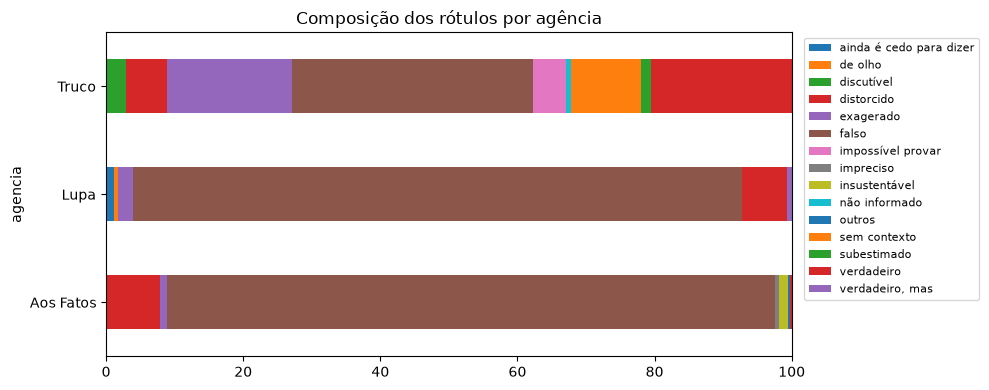

% de rótulo 'falso' por ano:
rotulo  False  True 
data                
2016     69.2   30.8
2017     64.5   35.5
2018     31.3   68.7
2019      9.1   90.9 

Palavras por alegação, por agência:
           count  mean    std  min   25%   50%   75%     max
agencia                                                     
Aos Fatos  361.0  22.4   20.8  4.0  12.0  17.0  27.0   305.0
Lupa       525.0  16.6   10.0  3.0  10.0  14.0  20.0   116.0
Truco      414.0  31.7  103.3  4.0  12.0  16.0  27.0  1599.0 

Mediana de palavras por rótulo:
rotulo
ainda é cedo para dizer     6.0
impreciso                   8.5
de olho                     9.0
subestimado                10.0
insustentável              13.0
outros                     13.0
impossível provar          13.5
falso                      15.0
verdadeiro                 15.0
exagerado                  16.0
verdadeiro, mas            16.5
distorcido                 17.0
discutível                 17.5
não informado              19.0
sem contexto 

In [8]:
# =============================================================
# 4. ANÁLISE BIVARIADA
# Cruzamentos entre agência, rótulo, tempo, tamanho e estrutura.
# =============================================================
import matplotlib.pyplot as plt

# --- 4.1 Rótulo x agência ------------------------------------
# Cada agência usa o seu vocabulário? Em que proporção?
prop = pd.crosstab(df_limpo["agencia"], df_limpo["rotulo"], normalize="index") * 100
print("Distribuição dos rótulos dentro de cada agência (%):")
print(prop.round(1).to_string(), "\n")

prop.plot(kind="barh", stacked=True, figsize=(10, 4),
          title="Composição dos rótulos por agência")
plt.legend(bbox_to_anchor=(1.01, 1), fontsize=8); plt.tight_layout(); plt.show()

# --- 4.2 Rótulo x tempo --------------------------------------
# A proporção de "falso" muda ao longo dos anos?
ano = pd.crosstab(df_limpo["data"].dt.year, df_limpo["rotulo"] == "falso",
                  normalize="index") * 100
print("% de rótulo 'falso' por ano:")
print(ano.round(1), "\n")

# --- 4.3 Tamanho da alegação x agência e x rótulo ------------
print("Palavras por alegação, por agência:")
print(df_limpo.groupby("agencia")["n_palavras"].describe().round(1), "\n")
print("Mediana de palavras por rótulo:")
print(df_limpo.groupby("rotulo")["n_palavras"].median().sort_values().to_string(), "\n")

# --- 4.4 Estrutura: URLs com várias alegações ----------------
print("Média de alegações por URL, por agência:")
print(df_limpo.groupby("agencia")["n_alegacoes_url"].mean().round(2), "\n")

multi = df_limpo[df_limpo["n_alegacoes_url"] > 1]
divergentes = multi.groupby("URL")["rotulo"].nunique()
print(f"URLs com várias alegações: {len(divergentes)}")
print(f"Delas, com rótulos diferentes na mesma página: {(divergentes > 1).sum()}\n")

# --- 4.5 Ausência de texto x tempo ---------------------------
print("Proporção de linhas com reviewBody, por ano:")
print(pd.crosstab(df_limpo["data"].dt.year, df_limpo["tem_review"],
                  normalize="index").round(2))

# 5. Extração do texto completo via URLs

In [ ]:
# =============================================================
# 5. EXTRAÇÃO DO TEXTO COMPLETO DAS CHECAGENS
# O reviewBody é só um resumo e falta em 539 linhas; o texto que
# vai para o índice do RAG é o conteúdo completo da página.
# Duas correções foram necessárias para chegar aqui:
#   - as URLs da Lupa migraram da piauí para agencialupa.org;
#   - sem cabeçalho de navegador, esse site responde 403.
# =============================================================
# !pip install -q trafilatura
%pip install requests trafilatura

import os, re, json, logging
import requests, trafilatura
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

logging.getLogger("urllib3").setLevel(logging.ERROR)
logging.getLogger("trafilatura").setLevel(logging.ERROR)

# --- 5.1 Configuração ----------------------------------------
CACHE = "textos_extraidos.json"
AMOSTRA = None        # None = todas as URLs; use um número para testar
WORKERS = 4

HEADERS = {
    "User-Agent": ("Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
                   "AppleWebKit/537.36 (KHTML, like Gecko) "
                   "Chrome/124.0 Safari/537.36"),
    "Accept-Language": "pt-BR,pt;q=0.9",
}

textos = json.load(open(CACHE, encoding="utf-8")) if os.path.exists(CACHE) else {}

# --- 5.2 Funções de extração ---------------------------------
def candidatos_lupa(url):
    """URLs antigas da piauí não resolvem mais; o domínio atual da Lupa sim."""
    m = re.search(r"/lupa/(\d{4}/\d{2}/\d{2}/[^/?]+)", url)
    return [f"https://www.agencialupa.org/{m.group(1)}"] if m else []

def extrair(url):
    """Tenta a URL original e, se falhar, o endereço atual da Lupa.
    Textos com menos de 50 palavras são descartados (página de erro ou paywall)."""
    for alvo in [url, *candidatos_lupa(url)]:
        try:
            r = requests.get(alvo, headers=HEADERS, timeout=20, allow_redirects=True)
            if r.status_code == 200:
                texto = trafilatura.extract(r.text, include_comments=False)
                if texto and len(texto.split()) > 50:
                    return url, texto
        except Exception:
            continue
    return url, None

# --- 5.3 Baixar apenas o que ainda não tem texto -------------
# Cada URL é baixada uma vez só, mesmo aparecendo em várias linhas.
# As que falharam antes voltam para a fila: basta reexecutar a célula.
urls = df_limpo["URL"].drop_duplicates().tolist()
faltam = [u for u in urls if textos.get(u) is None]
alvo = faltam if AMOSTRA is None else faltam[:AMOSTRA]
print(f"URLs únicas: {len(urls)} | já com texto: {len(urls) - len(faltam)} | "
      f"a baixar agora: {len(alvo)}")

with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    for i, (u, t) in enumerate(ex.map(extrair, alvo), 1):
        textos[u] = t
        if i % 50 == 0:
            print(f"  {i}/{len(alvo)}")
            json.dump(textos, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False)

json.dump(textos, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False)

# --- 5.4 Juntar ao dataset e avaliar -------------------------
df_limpo["texto_completo"] = df_limpo["URL"].map(textos)
df_limpo["n_palavras_texto"] = df_limpo["texto_completo"].str.split().str.len()

print("\nTaxa de sucesso por agência:")
print(df_limpo.groupby("agencia")["texto_completo"]
      .apply(lambda s: s.notna().mean()).round(2), "\n")

print("Palavras por texto extraído:")
print(df_limpo["n_palavras_texto"].describe().round(1), "\n")
print("Mediana por agência:")
print(df_limpo.groupby("agencia")["n_palavras_texto"].median(), "\n")

recuperadas = (~df_limpo["tem_review"] & df_limpo["texto_completo"].notna()).sum()
print(f"Linhas sem reviewBody recuperadas: {recuperadas} de 539")

# Comparação com o resumo original, para dimensionar o ganho:
df_limpo["n_palavras_review"] = df_limpo["reviewBody"].str.split().str.len()
print("\nMediana de palavras — resumo x texto completo:")
print(df_limpo[["n_palavras_review", "n_palavras_texto"]].median())

# --- 5.5 Salvar ----------------------------------------------
df_limpo.to_csv("factckbr_com_texto.csv", index=False)

# --- 5.6 A alegação aparece literalmente no texto extraído? ---
# A primeira checagem do Grounding Verifier exige trecho literal no documento.
import unicodedata, re

def norm(s, flexivel=False):
    if not isinstance(s, str):
        return ""
    s = unicodedata.normalize("NFKD", s.lower())
    if flexivel:
        s = re.sub(r"[^\w\s]", " ", s)   # ignora pontuação tipográfica
    return " ".join(s.split())

pares = list(zip(df_limpo["claimReviewed"], df_limpo["texto_completo"]))
estrito  = [norm(c)[:80] in norm(t) if isinstance(c, str) and isinstance(t, str) else None
            for c, t in pares]
flexivel = [norm(c, True)[:80] in norm(t, True) if isinstance(c, str) and isinstance(t, str) else None
            for c, t in pares]

comp = pd.DataFrame({"agencia": df_limpo["agencia"].values,
                     "estrito": estrito, "flexivel": flexivel})
print("Alegação presente literalmente no texto (%):")
print(comp.groupby("agencia")[["estrito", "flexivel"]].mean().astype(float).round(2), "\n")

# Quanto das falhas é problema de coleta e quanto é paráfrase genuína?
falhas = comp["flexivel"] == False
coleta = (df_limpo["claimReviewed"].str.contains(r"[a-záéíóúâêôãõç][A-ZÁÉÍÓÚÂÊÔÃÕÇ]", na=False).values
          | (df_limpo["claimReviewed"].str.isupper() == True).values)
print(f"Falhas: {falhas.sum()} | por erro de coleta: {(falhas & coleta).sum()} | "
      f"paráfrase genuína: {(falhas & ~coleta).sum()}")

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)

   ---------------------------------------- 2/2 [requests]

Note: you may need to restart the kernel to use updated packages.
URLs únicas: 983 | já com texto: 0 | a baixar agora: 983
  50/983
  100/983
  150/983
  200/983
  250/983
  300/983
  350/983
  400/983
  450/983
  500/983
  550/983
  600/983
  650/983
  700/983
  750/983
  800/983
  850/983
  900/983
  950/983

Taxa de sucesso por agência:
agencia
Aos Fatos    1.0
Lupa         1.0
Truco        1.0
Name: texto_completo, dtype: float64 

Palavras por texto extraído:
count    1311.0
mean     1137.5
std      1289.9
min       169.0
25%       334.0
50%       505.0
75%      1362.0
max      5202.0
Name: n_palavras_texto, dtype: float64 

Mediana por agência:
agencia
Aos Fatos     492.0
Lupa          334.0
Truco        2139.0
Name: n_palavras_texto, dtype: float64 

Linhas sem reviewBody recuperadas: 538 de 539

Medi

In [11]:
df_limpo.to_csv("factckbr_com_texto.csv", index=False)
print(list(df_limpo.columns))

['URL', 'Author', 'datePublished', 'claimReviewed', 'reviewBody', 'title', 'alternativeName', 'tem_alegacao', 'tem_review', 'agencia', 'data', 'rotulo', 'n_palavras', 'alegacao_suspeita', 'n_alegacoes_url', 'texto_completo', 'n_palavras_texto', 'n_palavras_review']


# 6. Conclusões e Próximos Passos

Esta análise avaliou a viabilidade do dataset **FACTCK.BR** como base de conhecimento (corpus de recuperação para RAG) no desenvolvimento do **Agente de Evidências**. Abaixo estão os principais aprendizados técnicos, diagnósticos dos dados e diretrizes para a arquitetura do sistema.

---

### 1. Diagnóstico de Qualidade e Tratamento Realizado

* **Ausência Crítica de Texto Resolvida:**
  * Originalmente, 41% das linhas (539 checagens) não dispunham do resumo da checagem (`reviewBody`), devido ao uso da string `"Empty"` pela Lupa e descontinuidades de coleta no Aos Fatos (especialmente no ciclo eleitoral de 2018).
  * Com o pipeline de raspagem via `trafilatura` (com remapeamento de domínios legados da Lupa para `agencialupa.org`), **538 das 539 linhas foram recuperadas**, atingindo 100% de cobertura de texto completo nas URLs acessíveis.
  * O ganho de densidade informacional foi massivo: a mediana de conteúdo saltou de **44 palavras** (resumo básico) para **505 palavras** (artigo completo), viabilizando estratégias robustas de segmentação em *chunks* e indexação vetorial.

* **Inconsistência nas Métricas Numéricas:**
  * As variáveis `ratingValue` e `bestRating` mostraram-se inadequadas para uso analítico ou operacional: as agências adotam escalas distintas (5, 6 e 8 níveis) e a Lupa preencheu a nota 4 em 100% de seus registros. O descarte dessas colunas foi a decisão correta para evitar distorções no modelo.

* **Ruído e Hipertrofia de Alegações:**
  * Foram identificadas anomalias em `claimReviewed`, com alegações contendo até mais de 1.500 palavras (casos em que o texto completo da matéria foi inadvertidamente alocado no campo da frase checada). O sinalizador `alegacao_suspeita` (>60 palavras) é essencial para filtragem pré-indexação.

---

### 2. Características Estruturais e Desafios para o RAG

* **Páginas com Múltiplas Alegações (Relação 1-para-N):**
  * O dataset possui 91 URLs que agrupam múltiplas alegações (chegando a médias de 3,1 alegações por URL na Lupa e 4,8 no Truco).
  * Em **61 dessas 91 URLs, há rótulos conflitantes ou distintos na mesma página** (por exemplo, alegações marcadas como falsas e outras como verdadeiras em uma mesma checagem de debate).
  * *Implicação para o RAG:* O sistema **não** pode fazer deduplicação simplista por URL nem atribuir o texto global a uma única alegação sem segmentação contextual refinada, sob risco de contaminação e respostas contraditórias.

* **Aderência Literal vs. Paráfrase:**
  * Entre 77% e 86% das alegações ocorrem com alta proximidade textual no corpo do artigo extraído.
  * A maior parte das 236 falhas de correspondência estrita decorre de paráfrases editoriais das próprias agências (210 casos), e não de falha na extração, validando que o *Grounding Verifier* precisará operar com flexibilidade semântica (embeddings) em vez de apenas busca por substrings exatas.

---

### 3. Limitações de Escopo

* **Janela Temporal Estática (2016–2019):**
  * O corpus é congelado no tempo, com forte concentração nas eleições de 2018 e temas políticos/eleitorais, apresentando um viés severo de seleção (cerca de 72% de vereditos "falso", superando 88% na Lupa e Aos Fatos).
  * Não há dados sobre temas recentes críticos (ex.: pandemia de COVID-19, eleições de 2022 ou desastres climáticos recentes).

---

### 4. Diretrizes para o Agente de Evidências

1. **Arquitetura de Corpus Híbrida:**
   * Utilizar o `factckbr_com_texto.csv` gerado como corpus estático de teste, benchmark e histórico de desinformação clássica brasileira.
   * Integrar a **Google Fact Check Tools API** para alimentação dinâmica e em tempo real de checagens posteriores a 2019.

2. **Estratégia de Chunking e Metadata Ingestion:**
   * Indexar os documentos completos segmentados por parágrafos/seções, mantendo como metadados associados: URL de origem, agência checadora, alegação pontual (`claimReviewed`), rótulo atribuído e data de publicação.

3. **Devolução Transparente e Atribuição:**
   * O agente deve sempre apresentar o rótulo original com atribuição explícita à agência (ex.: *"Segundo a Agência Lupa: falso"*), respeitando a taxonomia original de cada redação e fornecendo os trechos de evidência sem sintetizar julgamentos unilaterais de "verdadeiro/falso".